# Calibracao de Rosenzweig-MacArthur com Algoritmo Genetico

O protocolo separa repeticoes do AG com dados fixos e realizacoes independentes do ruido. Os parametros verdadeiros sao usados apenas na geracao e na avaliacao posterior.


## 1. Importacoes e configuracao dos dados

A geracao dos dados e a definicao da EDO sao reutilizadas de `data.py`.

In [16]:
from time import perf_counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.stats import qmc

from persistencia_ag import salvar_experimento, carregar_experimento

from data import gerar_dados_sinteticos, rosenzweig_macarthur

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 5)

In [17]:
# optimize: calibra e salva; load: recupera os resultados sem executar o AG.
MODO = "load"
# Caminho relativo a este notebook, mesmo quando iniciado na raiz do projeto.
PASTA_CODIGO = Path(__import__("data").__file__).resolve().parent
PASTA_RESULTADOS = PASTA_CODIGO.parent / "dados" / "resultados" / "ag_atual"
if MODO not in ("optimize", "load"):
    raise ValueError("MODO deve ser optimize ou load.")
experimento_carregado = carregar_experimento(PASTA_RESULTADOS) if MODO == "load" else None

# Configuracao centralizada do experimento de dados.
NOMES_PARAMETROS = np.array(["r", "K", "a", "h", "e", "m"])
NOMES_POPULACOES = ("N", "P")

theta_true = np.array([1.0, 100.0, 0.05, 0.2, 0.5, 0.5])
y0 = np.array([40.0, 10.0])
CONFIG_DADOS = {
    "t_span": (0.0, 30.0),
    "n_obs": 50,
    "ruido": 0.02,
    "seed": 2026,
    "metodo": "DOP853",
    "rtol": 1e-11,
    "atol": 1e-13,
}

if MODO == "load":
    meta = experimento_carregado["metadados"]
    CONFIG_DADOS = meta["config_dados"]
    theta_true = np.asarray(meta["theta_true"])
    y0 = np.asarray(meta["y0"])
    df_dados = pd.DataFrame(meta["dados_visualizacao"])
else:
    df_dados = gerar_dados_sinteticos(
        modelo=rosenzweig_macarthur, parametros=theta_true, y0=y0,
        nomes_variaveis=list(NOMES_POPULACOES), **CONFIG_DADOS,
    )

t_obs = df_dados["t"].to_numpy()
y_obs = df_dados[["N_obs", "P_obs"]].to_numpy()
y_ref = df_dados[["N_true", "P_true"]].to_numpy()

display(df_dados.head())

,t,N_obs,N_true,P_obs,P_true
0,0.00000,39.46434,40.00000,10.08450,10.00000
1,0.61224,43.81714,45.09788,12.12953,11.63928
2,1.22449,48.33928,47.90819,13.84980,13.95238
3,1.83673,47.68508,47.89576,17.00071,16.89399
4,2.44898,44.88415,45.06492,20.16861,20.24796


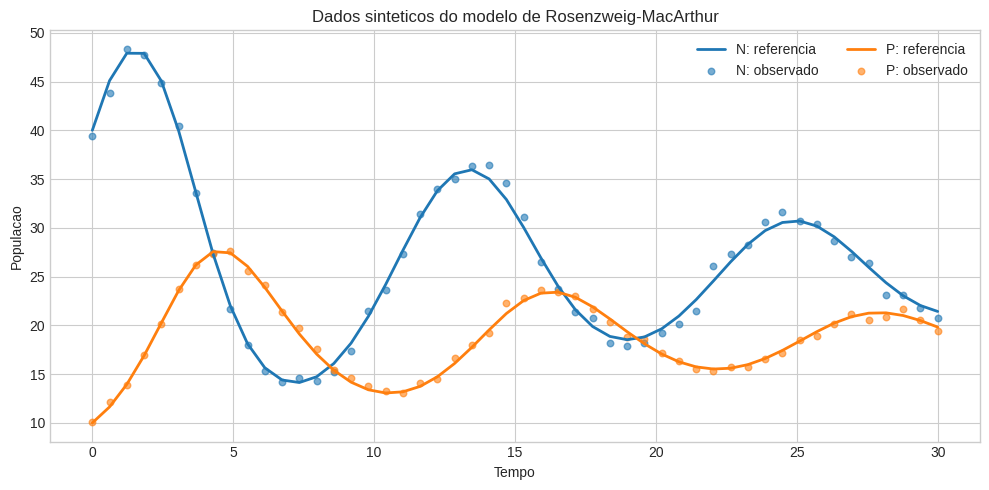

In [18]:
# Grafico 1: dados sinteticos.
fig, ax = plt.subplots(figsize=(10, 5))
cores = ("tab:blue", "tab:orange")
for indice, (nome, cor) in enumerate(zip(NOMES_POPULACOES, cores)):
    ax.plot(t_obs, y_ref[:, indice], color=cor, lw=2, label=f"{nome}: referencia")
    ax.scatter(t_obs, y_obs[:, indice], color=cor, s=22, alpha=0.60, label=f"{nome}: observado")
ax.set(title="Dados sinteticos do modelo de Rosenzweig-MacArthur", xlabel="Tempo", ylabel="Populacao")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 2. Problema de calibracao

Os seis parametros sao estimados dentro dos limites abaixo. A funcao objetivo nao acessa `theta_true`: ela compara somente a solucao candidata com `y_obs` nos mesmos instantes de observacao. A normalizacao opcional usa a amplitude de cada populacao observada.

A referencia usa DOP853 com tolerancias mais estritas; a inversao usa RK45. Isso reduz o compartilhamento do erro numerico, mas o experimento continua controlado e usa o mesmo modelo matematico, sem avaliar erro de modelo.


In [19]:
LIMITES_INFERIORES = np.array([0.2, 40.0, 0.005, 0.02, 0.1, 0.05])
LIMITES_SUPERIORES = np.array([2.0, 200.0, 0.15, 1.0, 1.0, 1.5])
LIMITES = np.column_stack((LIMITES_INFERIORES, LIMITES_SUPERIORES))
NORMALIZAR_RESIDUOS = True
if MODO == "load":
    LIMITES = np.asarray(meta["config_ag"]["limites"])
    LIMITES_INFERIORES, LIMITES_SUPERIORES = LIMITES.T
    NORMALIZAR_RESIDUOS = meta["normalizar_residuos"]
PENALIDADE = 1e12

def simular_modelo(parametros):
    """Resolve o modelo nos tempos observados; retorna None para trajetorias invalidas."""
    try:
        solucao = solve_ivp(
            rosenzweig_macarthur,
            CONFIG_DADOS["t_span"],
            y0,
            t_eval=t_obs,
            args=tuple(np.asarray(parametros, dtype=float)),
            method="RK45",
            rtol=1e-8,
            atol=1e-10,
        )
    except (FloatingPointError, OverflowError, ValueError):
        return None

    if not solucao.success or solucao.y.shape != (2, len(t_obs)):
        return None
    predicao = solucao.y.T
    if not np.all(np.isfinite(predicao)) or np.any(predicao < 0.0):
        return None
    return predicao

def criar_objetivo(observacoes):
    """Captura os dados de uma realizacao sem depender de variaveis globais mutaveis."""
    observacoes = np.asarray(observacoes, dtype=float).copy()
    escala = np.ptp(observacoes, axis=0)
    escala = np.where(escala > 0, escala, np.maximum(np.max(np.abs(observacoes), axis=0), 1.0))

    def objetivo(parametros):
        parametros = np.asarray(parametros, dtype=float)
        if parametros.shape != (len(NOMES_PARAMETROS),) or not np.all(np.isfinite(parametros)):
            return PENALIDADE
        if np.any(parametros < LIMITES_INFERIORES) or np.any(parametros > LIMITES_SUPERIORES):
            return PENALIDADE
        predicao = simular_modelo(parametros)
        if predicao is None:
            return PENALIDADE
        residuos = predicao - observacoes
        if NORMALIZAR_RESIDUOS:
            residuos = residuos / escala
        mse = np.mean(residuos ** 2)
        return float(mse) if np.isfinite(mse) else PENALIDADE
    return objetivo

funcao_objetivo = criar_objetivo(y_obs)

print(f"MSE nos parametros verdadeiros (referencia, nao usado pelo AG): {funcao_objetivo(theta_true):.6g}")

MSE nos parametros verdadeiros (referencia, nao usado pelo AG): 0.000412031


## 3. Configuracao e implementacao do Algoritmo Genetico

A populacao inicial e amostrada por hipercubo latino (LHS), com um ponto em cada estrato de cada parametro, e escalada para os limites fisicos. A seed de cada execucao torna a amostragem reproduzivel. O AG usa selecao por torneio, cruzamento blend, mutacao gaussiana limitada ao dominio e elitismo. Os valores sao reais em suas unidades fisicas.

In [20]:
CONFIG_AG = {
    "tamanho_populacao": 100,
    "max_geracoes": 150,
    "prob_cruzamento": 0.90,
    "prob_mutacao": 0.25,
    "escala_mutacao": 0.05,
    "tamanho_torneio": 3,
    "elitismo": 3,
    "paciencia": 50,
    "tolerancia": 1e-8,
    "limites": LIMITES,
    "n_execucoes": 30,
    "seed_base": 3100,
}

# Configuracao separada para verificacoes curtas; nao altera CONFIG_AG.
CONFIG_TESTE_RAPIDO = {**CONFIG_AG, "tamanho_populacao": 12, "max_geracoes": 5, "n_execucoes": 2, "paciencia": 5}

def avaliar_populacao(populacao, objetivo, contador):
    """Avalia a populacao e atualiza o contador mutavel de chamadas da funcao objetivo."""
    fitness = np.empty(len(populacao), dtype=float)
    for indice, individuo in enumerate(populacao):
        fitness[indice] = objetivo(individuo)
        contador[0] += 1
    return fitness

def selecionar_torneio(fitness, tamanho_torneio, rng):
    """Retorna o indice do melhor competidor sorteado."""
    candidatos = rng.integers(0, len(fitness), size=tamanho_torneio)
    return candidatos[np.argmin(fitness[candidatos])]

def cruzar_blend(pai_a, pai_b, probabilidade, rng):
    """Aplica cruzamento aritmetico com mistura por parametro."""
    if rng.random() >= probabilidade:
        return pai_a.copy(), pai_b.copy()
    mistura = rng.uniform(-0.25, 1.25, size=len(pai_a))
    filho_a = mistura * pai_a + (1.0 - mistura) * pai_b
    filho_b = mistura * pai_b + (1.0 - mistura) * pai_a
    return filho_a, filho_b

def mutar(individuo, configuracao, rng):
    """Aplica mutacao gaussiana independente e repara os limites."""
    limites = np.asarray(configuracao["limites"], dtype=float)
    mascara = rng.random(len(individuo)) < configuracao["prob_mutacao"]
    desvio = configuracao["escala_mutacao"] * (limites[:, 1] - limites[:, 0])
    individuo = individuo.copy()
    individuo[mascara] += rng.normal(0.0, desvio[mascara])
    return np.clip(individuo, limites[:, 0], limites[:, 1])

def executar_ag(objetivo, configuracao, seed):
    """Executa uma rodada independente do AG e devolve metricas e historicos."""
    tamanho_populacao = configuracao["tamanho_populacao"]
    elitismo = configuracao["elitismo"]
    if not 1 <= elitismo < tamanho_populacao:
        raise ValueError("elitismo deve estar entre 1 e tamanho_populacao - 1.")

    limites = np.asarray(configuracao["limites"], dtype=float)
    if limites.shape != (len(NOMES_PARAMETROS), 2) or np.any(limites[:, 0] >= limites[:, 1]):
        raise ValueError("limites invalidos.")

    rng = np.random.default_rng(seed)
    amostrador = qmc.LatinHypercube(d=len(limites), seed=seed)
    amostra_unitaria = amostrador.random(n=tamanho_populacao)
    populacao = qmc.scale(amostra_unitaria, limites[:, 0], limites[:, 1])
    contador = [0]
    fitness = avaliar_populacao(populacao, objetivo, contador)
    historico_melhor, historico_medio = [], []
    melhor_global = np.inf
    sem_melhoria = 0

    for geracao in range(configuracao["max_geracoes"] + 1):
        ordem = np.argsort(fitness)
        melhor_atual = float(fitness[ordem[0]])
        historico_melhor.append(melhor_atual)
        historico_medio.append(float(np.mean(fitness)))

        if melhor_atual < melhor_global - configuracao["tolerancia"]:
            melhor_global = melhor_atual
            sem_melhoria = 0
        else:
            sem_melhoria += 1
        if geracao == configuracao["max_geracoes"] or sem_melhoria >= configuracao["paciencia"]:
            break

        proxima = [populacao[indice].copy() for indice in ordem[:elitismo]]
        while len(proxima) < tamanho_populacao:
            pai_a = populacao[selecionar_torneio(fitness, configuracao["tamanho_torneio"], rng)]
            pai_b = populacao[selecionar_torneio(fitness, configuracao["tamanho_torneio"], rng)]
            filho_a, filho_b = cruzar_blend(pai_a, pai_b, configuracao["prob_cruzamento"], rng)
            for filho in (filho_a, filho_b):
                proxima.append(mutar(filho, configuracao, rng))
                if len(proxima) == tamanho_populacao:
                    break
        populacao = np.asarray(proxima)
        fitness = np.concatenate((
            fitness[ordem[:elitismo]],
            avaliar_populacao(populacao[elitismo:], objetivo, contador),
        ))

    indice_melhor = int(np.argmin(fitness))
    return {
        "parametros": populacao[indice_melhor].copy(),
        "objetivo": float(fitness[indice_melhor]),
        "historico_melhor": np.asarray(historico_melhor),
        "historico_medio": np.asarray(historico_medio),
        "avaliacoes": contador[0],
        "geracao_final": geracao,
        "seed": seed,
    }
if MODO == "load":
    CONFIG_AG = {**meta["config_ag"], "limites": LIMITES}


## 4. Execucao e persistencia

Defina `MODO` e `PASTA_RESULTADOS` na configuracao inicial. Em `optimize`, cada calibracao concluida atualiza `experimento.json` atomicamente, incluindo parametros, historicos, dados e configuracoes. Em `load`, esses dados sao restaurados para as tabelas e graficos, sem executar o AG. As simulacoes para avaliar e desenhar as trajetorias continuam sendo realizadas.

Uma pasta existente e protegida contra sobrescrita: escolha outra pasta para um novo experimento. Se houver interrupcao, `load` permite analisar as calibracoes ja salvas; a rodada interrompida nao e recuperada e nao ha retomada automatica. Nao use a mesma pasta em duas execucoes simultaneas.

Os resultados que ja estao apenas na memoria do kernel podem ser salvos executando a definicao de `salvar_experimento` e usando os metadados correspondentes; alterar o notebook nao salva retroativamente essas variaveis.


In [21]:
CONFIG_PROTOCOLO = {
    "niveis_ruido": (0.0, 0.02, 0.05),
    "n_realizacoes": 3,
    "seed_dados_base": CONFIG_DADOS["seed"],
    "tolerancia_sucesso": 0.10,
}
CONFIG_PROTOCOLO_RAPIDO = {
    **CONFIG_PROTOCOLO, "niveis_ruido": (0.0, 0.02), "n_realizacoes": 2,
}
if MODO == "load":
    CONFIG_PROTOCOLO = meta["config_protocolo"]


In [22]:
def executar_experimento(configuracao, protocolo=CONFIG_PROTOCOLO, pasta=PASTA_RESULTADOS):
    if (Path(pasta) / "experimento.json").exists():
        raise FileExistsError("Esta pasta ja possui resultados. Use MODO='load' ou escolha uma nova PASTA_RESULTADOS.")
    metadados = {
        "config_ag": configuracao, "config_protocolo": protocolo,
        "config_dados": CONFIG_DADOS, "theta_true": theta_true, "y0": y0,
        "normalizar_residuos": NORMALIZAR_RESIDUOS,
        "dados_visualizacao": df_dados.to_dict(orient="list"),
        "modelo": "rosenzweig_macarthur", "inversao": {"metodo": "RK45", "rtol": 1e-8, "atol": 1e-10},
    }
    resultados = []
    for ruido in protocolo["niveis_ruido"]:
        # Sem ruido, repetir os mesmos dados nao acrescenta informacao.
        n_realizacoes = 1 if ruido == 0 else protocolo["n_realizacoes"]
        for realizacao in range(n_realizacoes):
            seed_dados = protocolo["seed_dados_base"] + realizacao
            config_dados = {**CONFIG_DADOS, "ruido": ruido, "seed": seed_dados}
            dados = gerar_dados_sinteticos(
                rosenzweig_macarthur, theta_true, y0,
                nomes_variaveis=list(NOMES_POPULACOES), **config_dados,
            )
            observacoes = dados[["N_obs", "P_obs"]].to_numpy()
            referencia = dados[["N_true", "P_true"]].to_numpy()
            objetivo = criar_objetivo(observacoes)
            for execucao in range(configuracao["n_execucoes"]):
                seed = configuracao["seed_base"] + execucao
                inicio = perf_counter()
                resultado = executar_ag(objetivo, configuracao, seed)
                resultado.update(
                    tempo_segundos=perf_counter() - inicio, execucao=execucao + 1,
                    ruido=ruido, realizacao=realizacao, seed_dados=seed_dados,
                    observacoes=observacoes, referencia=referencia,
                    tolerancia_sucesso=protocolo["tolerancia_sucesso"],
                )
                resultados.append(resultado)
                salvar_experimento(pasta, metadados, resultados)
                print(f"Ruido={ruido:.0%}, realizacao={realizacao}, AG={execucao+1}: "
                    f"objetivo={resultado['objetivo']:.6g}, tempo={resultado['tempo_segundos']:.2f} s")
    salvar_experimento(pasta, metadados, resultados, completo=True)
    return resultados

if MODO == "load":
    resultados_ag = experimento_carregado["resultados"]
    estado = "completo" if experimento_carregado["completo"] else "parcial"
    print(f"Carregadas {len(resultados_ag)} calibracoes; experimento {estado}.")
else:
    resultados_ag = executar_experimento(CONFIG_AG, CONFIG_PROTOCOLO)
    # resultados_ag = executar_experimento(
    # CONFIG_TESTE_RAPIDO,
    # CONFIG_PROTOCOLO_RAPIDO,
    # )


Carregadas 210 calibracoes; experimento completo.


## 5. Avaliacao estatistica

O objetivo mede o ajuste aos dados ruidosos. Os erros de parametro abaixo usam `theta_true` somente depois da otimizacao, para avaliar a recuperacao em um experimento sintetico.

In [23]:
linhas = []
for resultado in resultados_ag:
    linha = {
        "ruido": resultado["ruido"],
        "realizacao": resultado["realizacao"],
        "seed_dados": resultado["seed_dados"],
        "execucao": resultado["execucao"],
        "seed": resultado["seed"],
        "objetivo": resultado["objetivo"],
        "tempo_segundos": resultado["tempo_segundos"],
        "avaliacoes": resultado["avaliacoes"],
        "geracao_final": resultado["geracao_final"],
    }
    erros = np.abs(resultado["parametros"] - theta_true) / np.abs(theta_true)
    linha["erro_relativo_maximo"] = float(erros.max())
    linha["sucesso"] = bool(erros.max() <= resultado["tolerancia_sucesso"])
    predicao = simular_modelo(resultado["parametros"])
    linha["rmse_trajetoria"] = (float(np.sqrt(np.mean((predicao - resultado["referencia"]) ** 2)))
                                if predicao is not None else np.nan)
    for nome, erro in zip(NOMES_PARAMETROS, erros):
        linha[f"erro_relativo_{nome}"] = erro
    linha.update(dict(zip(NOMES_PARAMETROS, resultado["parametros"])))
    linhas.append(linha)

tabela_execucoes = pd.DataFrame(linhas)
# Resumos condicionais: nao misturar objetivos de conjuntos de dados diferentes.
tabela_por_realizacao = tabela_execucoes.groupby(["ruido", "realizacao"]).agg(
    objetivo_mediano=("objetivo", "median"),
    erro_mediano=("erro_relativo_maximo", "median"),
    erro_dp_ag=("erro_relativo_maximo", "std"),
    taxa_sucesso=("sucesso", "mean"),
    rmse_mediano=("rmse_trajetoria", "median"),
    tempo_medio=("tempo_segundos", "mean"),
    avaliacoes_medias=("avaliacoes", "mean"),
)
display(tabela_por_realizacao)
tabela_por_ruido = tabela_por_realizacao.groupby("ruido").agg(
    erro_mediano=("erro_mediano", "median"),
    dp_entre_realizacoes=("erro_mediano", "std"),
    taxa_sucesso_media=("taxa_sucesso", "mean"),
)
display(tabela_por_ruido)

# Graficos detalhados referem-se a um unico conjunto de dados.
# None seleciona o primeiro cenario salvo; ou informe (ruido, realizacao).
CENARIO_VISUALIZACAO = None
if CENARIO_VISUALIZACAO is None:
    CENARIO_VISUALIZACAO = (resultados_ag[0]["ruido"], resultados_ag[0]["realizacao"])

mascara = ((tabela_execucoes["ruido"] == CENARIO_VISUALIZACAO[0]) &
           (tabela_execucoes["realizacao"] == CENARIO_VISUALIZACAO[1]))
tabela_cenario = tabela_execucoes.loc[mascara]
if tabela_cenario.empty:
    raise ValueError("Escolha um CENARIO_VISUALIZACAO presente no protocolo.")
resultados_cenario = [resultados_ag[i] for i in tabela_cenario.index]
y_obs_cenario = resultados_cenario[0]["observacoes"]
parametros_estimados = tabela_cenario[NOMES_PARAMETROS]
parametros_medios = parametros_estimados.mean().to_numpy()
parametros_dp = parametros_estimados.std(ddof=1).to_numpy()

tabela_objetivo = pd.DataFrame({
    "media": [tabela_cenario["objetivo"].mean()],
    "desvio_padrao": [tabela_cenario["objetivo"].std(ddof=1)],
    "mediana": [tabela_cenario["objetivo"].median()],
    "minimo": [tabela_cenario["objetivo"].min()],
    "maximo": [tabela_cenario["objetivo"].max()],
})

tabela_parametros = pd.DataFrame({
    "verdadeiro": theta_true,
    "estimativa_media": parametros_medios,
    "desvio_padrao": parametros_dp,
    "erro_absoluto": np.abs(parametros_medios - theta_true),
    "erro_relativo": np.abs(parametros_medios - theta_true) / np.abs(theta_true),
}, index=NOMES_PARAMETROS)

tabela_tempo = pd.DataFrame({
    "tempo_medio_segundos": [tabela_cenario["tempo_segundos"].mean()],
    "tempo_dp_segundos": [tabela_cenario["tempo_segundos"].std(ddof=1)],
})

print("Resultados por execucao")
display(tabela_execucoes)
print("\nObjetivo: ajuste aos dados observados")
display(tabela_objetivo)
print("\nRecuperacao dos parametros verdadeiros")
display(tabela_parametros)
print("\nCusto computacional")
display(tabela_tempo)

objetivo_mediano  erro_mediano  erro_dp_ag  taxa_sucesso  \
ruido realizacao                                                             
0.00  0                    0.00040       0.53320     0.37932       0.03333   
0.02  0                    0.00072       0.53143     0.33430       0.00000   
      1                    0.00075       0.61415     0.36038       0.00000   
      2                    0.00083       0.45530     0.36118       0.06667   
0.05  0                    0.00276       0.59744     0.32928       0.00000   
      1                    0.00269       0.60127     0.31562       0.00000   
      2                    0.00317       0.63443     0.32851       0.00000   

                  rmse_mediano  tempo_medio  avaliacoes_medias  
ruido realizacao                                                
0.00  0                0.55480    158.95306        14042.13333  
0.02  0                0.50881    155.41882        13722.03333  
      1                0.56288    158.22713        13971.00000  
      2                0.51916    159.39512        14071.23333  
0.05  0                0.60814    161.38628        14113.26667  
      1                0.69156    154.58449        14139.13333  
      2                0.64038    160.63409        14472.16667

,erro_mediano,dp_entre_realizacoes,taxa_sucesso_media
ruido,,,
0.00,0.53320,NaN,0.03333
0.02,0.53143,0.07945,0.02222
0.05,0.60127,0.02034,0.00000


Resultados por execucao


,ruido,realizacao,seed_dados,execucao,seed,objetivo,tempo_segundos,avaliacoes,geracao_final,erro_relativo_maximo,...,erro_relativo_a,erro_relativo_h,erro_relativo_e,erro_relativo_m,r,K,a,h,e,m
0,0.00,0,2026,1,3100,0.00082,164.01804,14650,150,1.03719,...,0.22110,1.03719,0.50194,0.39703,1.05948,75.42519,0.06105,0.40744,0.75097,0.69851
1,0.00,0,2026,2,3101,0.00002,163.79743,14553,149,0.08339,...,0.01564,0.08339,0.07217,0.04342,0.98061,97.60021,0.04922,0.21668,0.53608,0.52171
2,0.00,0,2026,3,3102,0.00066,164.22428,14650,150,0.44493,...,0.21451,0.44493,0.05879,0.03650,0.83858,123.68442,0.03927,0.11101,0.52940,0.48175
3,0.00,0,2026,4,3103,0.00042,163.97330,14650,150,0.82488,...,0.06158,0.82488,0.50138,0.33532,0.97995,79.54394,0.05308,0.36498,0.75069,0.66766
4,0.00,0,2026,5,3104,0.00003,163.80187,14650,150,0.17344,...,0.04478,0.17344,0.05400,0.05001,1.02158,93.90549,0.05224,0.23469,0.52700,0.52500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
205,0.05,2,2028,26,3125,0.00272,164.64631,14650,150,0.35429,...,0.04829,0.35429,0.14640,0.10804,0.97249,118.12020,0.04759,0.12914,0.42680,0.44598
206,0.05,2,2028,27,3126,0.00301,163.52256,14650,150,0.62283,...,0.13806,0.62283,0.25432,0.21232,1.04709,81.68339,0.05690,0.32457,0.62716,0.60616
207,0.05,2,2028,28,3127,0.00307,159.51479,14650,150,0.70735,...,0.14614,0.70735,0.31116,0.25716,1.03678,80.86708,0.05731,0.34147,0.65558,0.62858
208,0.05,2,2028,29,3128,0.00277,162.34543,14650,150,0.33687,...,0.08218,0.33687,0.11831,0.10681,1.02788,89.25946,0.05411,0.26737,0.55916,0.55340



Objetivo: ajuste aos dados observados


,media,desvio_padrao,mediana,minimo,maximo
0,0.00045,0.00038,0.0004,0.00002,0.00139



Recuperacao dos parametros verdadeiros


,verdadeiro,estimativa_media,desvio_padrao,erro_absoluto,erro_relativo
r,1.00,1.03387,0.07200,0.03387,0.03387
K,100.00,86.26027,11.78055,13.73973,0.13740
a,0.05,0.05555,0.00625,0.00555,0.11097
h,0.20,0.30612,0.08971,0.10612,0.53059
e,0.50,0.62990,0.12426,0.12990,0.25980
m,0.50,0.60045,0.08877,0.10045,0.20090



Custo computacional


,tempo_medio_segundos,tempo_dp_segundos
0,158.95306,15.33258


## 6. Visualizacoes dos resultados

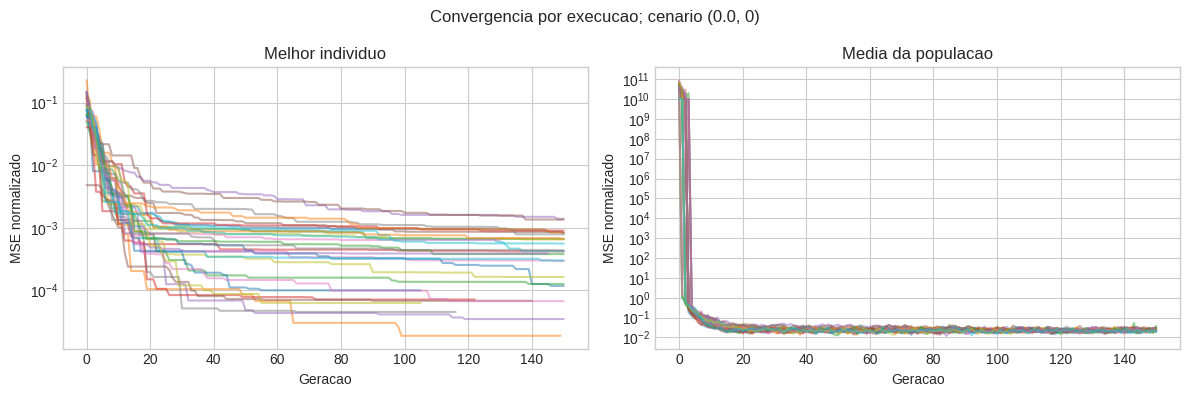

In [24]:
# Melhor individuo e media da populacao: apenas geracoes efetivamente executadas.
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for resultado in resultados_cenario:
    g = np.arange(len(resultado["historico_melhor"]))
    eixos[0].plot(g, resultado["historico_melhor"], alpha=0.5)
    eixos[1].plot(g, resultado["historico_medio"], alpha=0.5)
for eixo, titulo in zip(eixos, ("Melhor individuo", "Media da populacao")):
    eixo.set(title=titulo, xlabel="Geracao", ylabel="MSE normalizado" if NORMALIZAR_RESIDUOS else "MSE")
    eixo.set_yscale("symlog", linthresh=1e-8)
fig.suptitle(f"Convergencia por execucao; cenario {CENARIO_VISUALIZACAO}")
fig.tight_layout()
plt.show()


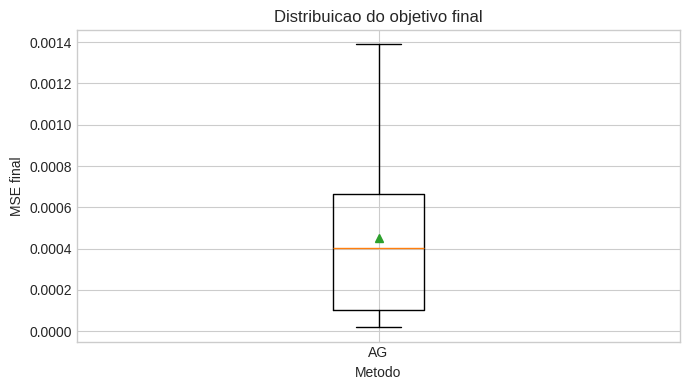

In [25]:
# Grafico 3: distribuicao dos erros finais de ajuste.
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(tabela_cenario["objetivo"], tick_labels=["AG"], showmeans=True)
ax.set(title="Distribuicao do objetivo final", xlabel="Metodo", ylabel="MSE final")
plt.tight_layout()
plt.show()

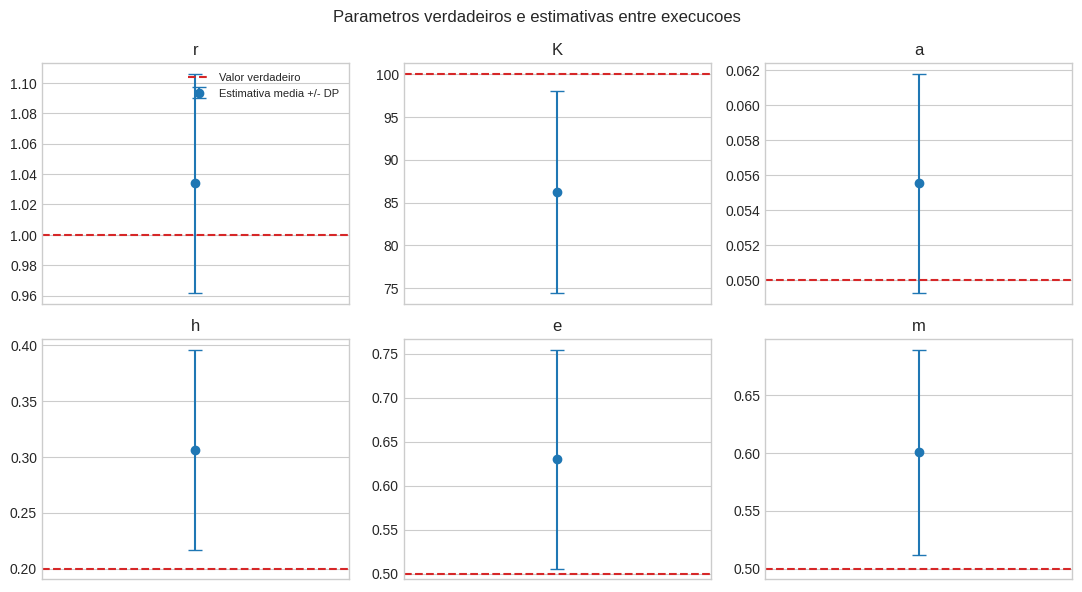

In [26]:
# Grafico 4: cada painel preserva a escala fisica de seu parametro.
fig, eixos = plt.subplots(2, 3, figsize=(11, 6))
for indice, eixo in enumerate(eixos.flat):
    eixo.errorbar(1, parametros_medios[indice], yerr=parametros_dp[indice], fmt="o", capsize=5, color="tab:blue", label="Estimativa media +/- DP")
    eixo.axhline(theta_true[indice], color="tab:red", ls="--", label="Valor verdadeiro")
    eixo.set(title=NOMES_PARAMETROS[indice], xlim=(0.5, 1.5), xticks=[])
eixos[0, 0].legend(fontsize=8)
fig.suptitle("Parametros verdadeiros e estimativas entre execucoes")
fig.tight_layout()
plt.show()

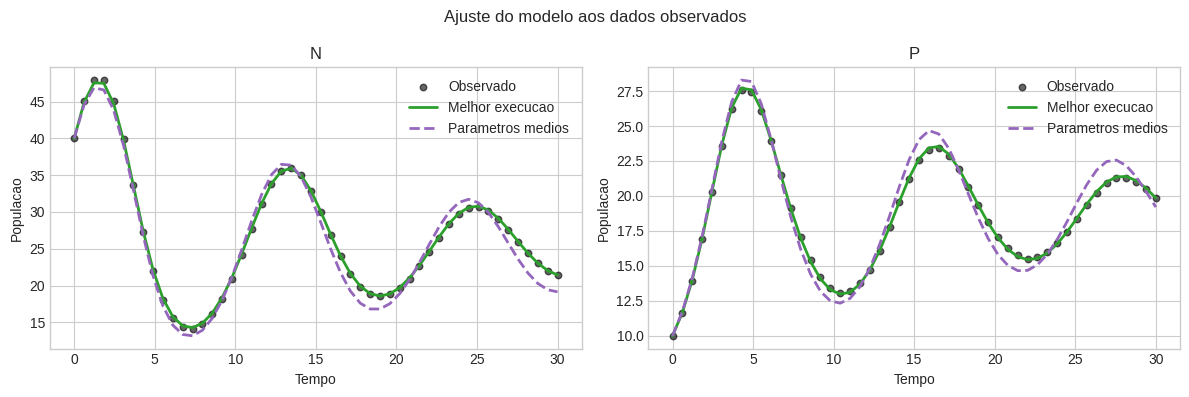

In [27]:
# Grafico 5: ajuste do melhor vetor e do vetor medio.
indice_melhor = int(tabela_cenario["objetivo"].idxmin())
melhor_resultado = resultados_ag[indice_melhor]
predicao_melhor = simular_modelo(melhor_resultado["parametros"])
predicao_media = simular_modelo(parametros_medios)

fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for indice, eixo in enumerate(eixos):
    nome = NOMES_POPULACOES[indice]
    eixo.scatter(t_obs, y_obs_cenario[:, indice], color="black", s=22, alpha=0.6, label="Observado")
    eixo.plot(t_obs, predicao_melhor[:, indice], color="tab:green", lw=2, label="Melhor execucao")
    if predicao_media is not None:
        eixo.plot(t_obs, predicao_media[:, indice], color="tab:purple", ls="--", lw=2, label="Parametros medios")
    eixo.set(title=nome, xlabel="Tempo", ylabel="Populacao")
    eixo.legend()
fig.suptitle("Ajuste do modelo aos dados observados")
fig.tight_layout()
plt.show()

### Distribuicao dos parametros por nivel de ruido

Cada figura mostra um nivel de ruido, com os seis parametros em uma grade 2 x 3. Cada otimizacao contribui uma estimativa final; as realizacoes dos dados daquele nivel sao agrupadas. A dispersao combina a variabilidade do AG e, quando houver varias realizacoes, o efeito do ruido. A linha tracejada indica o valor verdadeiro. As classes e os limites de cada parametro sao os mesmos em todas as figuras para facilitar a comparacao.


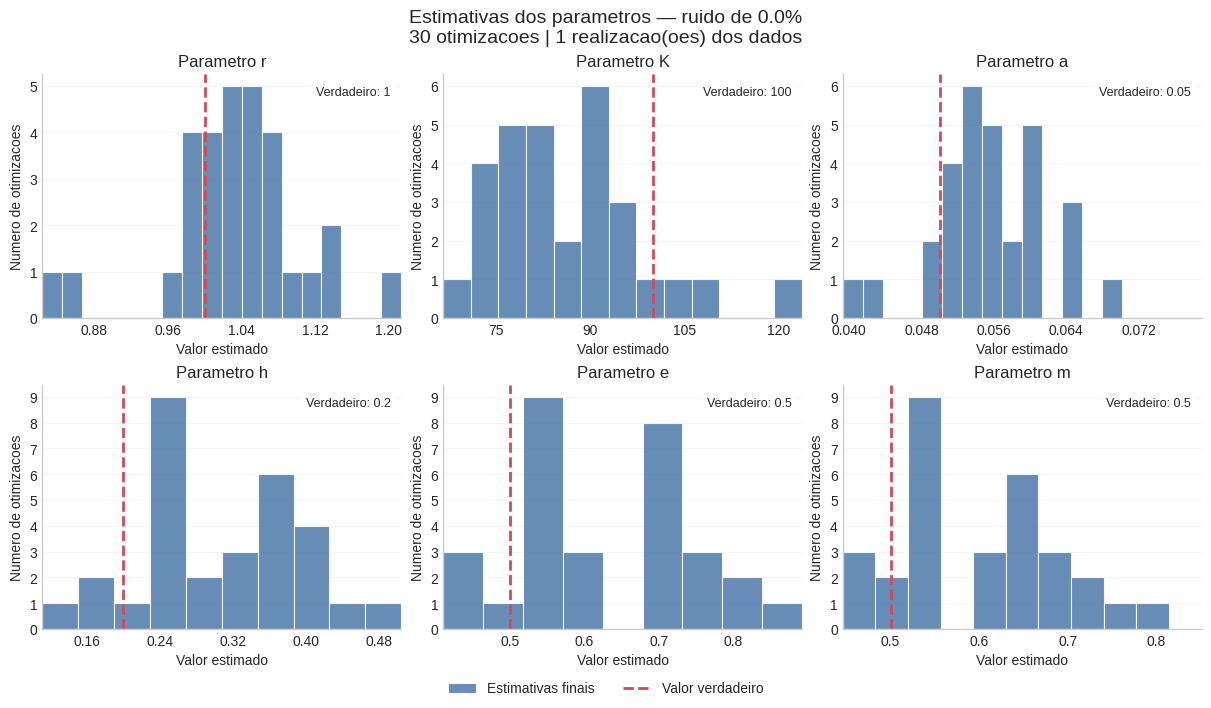

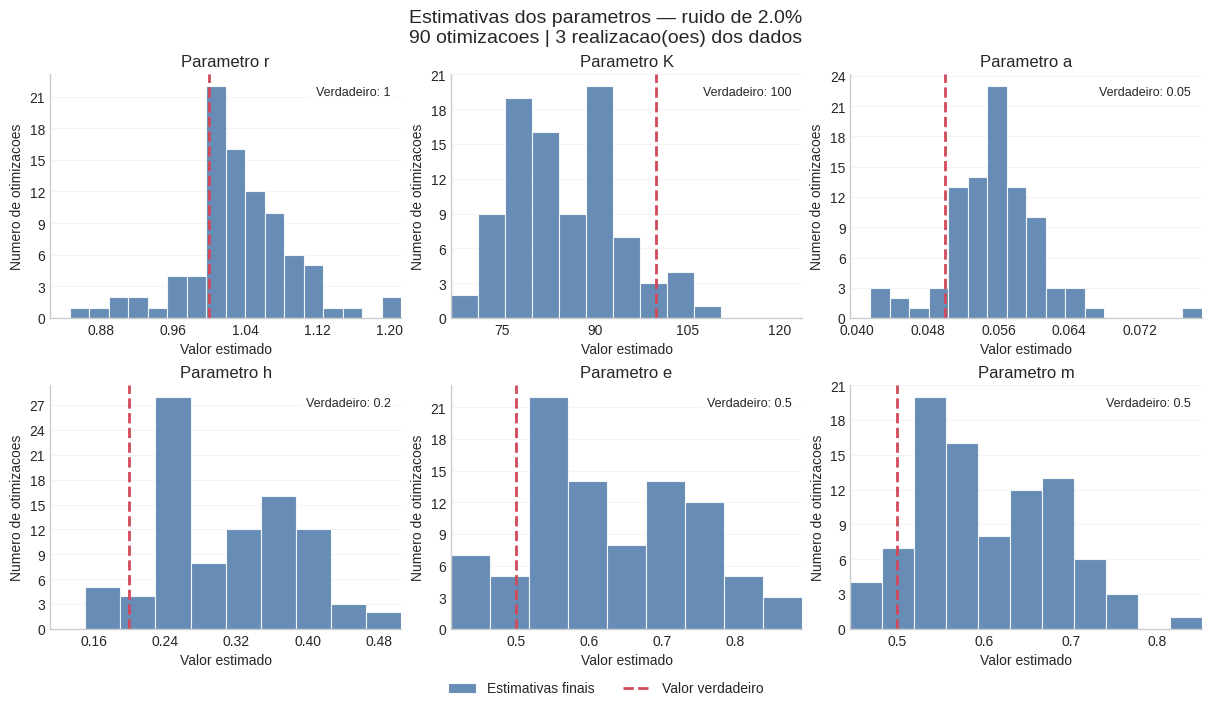

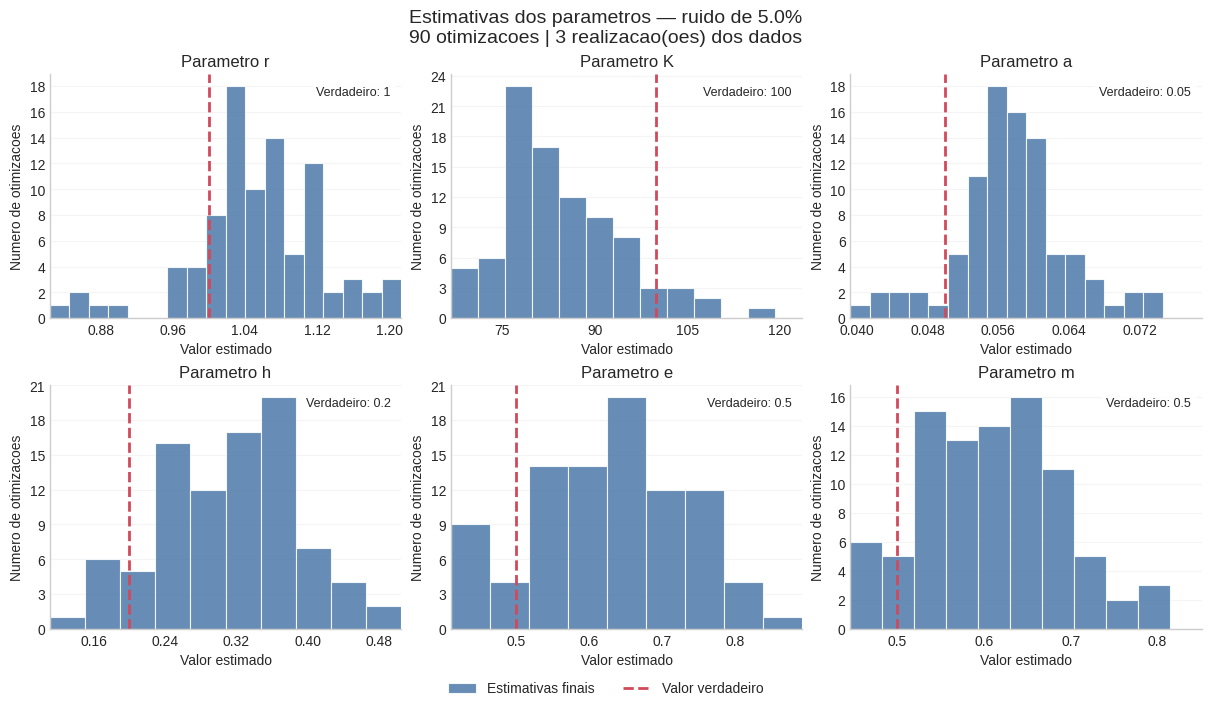

In [28]:
# Uma figura por nivel de ruido, usando todas as otimizacoes desse nivel.
niveis_histograma = np.sort(tabela_execucoes["ruido"].unique())
# Classes e limites comuns por parametro permitem comparar figuras diferentes.
bordas_histograma = {}
for indice, nome in enumerate(NOMES_PARAMETROS):
    valores = tabela_execucoes[nome].to_numpy(dtype=float)
    valores = valores[np.isfinite(valores)]
    bordas_histograma[nome] = np.histogram_bin_edges(
        np.append(valores, theta_true[indice]), bins="auto",
    )

for ruido in niveis_histograma:
    grupo = tabela_execucoes.loc[tabela_execucoes["ruido"] == ruido]
    n_realizacoes = grupo["realizacao"].nunique()
    fig, eixos = plt.subplots(2, 3, figsize=(12, 7), layout="constrained")
    for indice, (nome, eixo) in enumerate(zip(NOMES_PARAMETROS, eixos.flat)):
        valores = grupo[nome].to_numpy(dtype=float)
        valores = valores[np.isfinite(valores)]
        bordas = bordas_histograma[nome]
        eixo.hist(valores, bins=bordas, color="#4C78A8", alpha=0.85,
                  edgecolor="white", linewidth=0.8, label="Estimativas finais")
        eixo.axvline(theta_true[indice], color="#D1495B", linestyle="--",
                     linewidth=2, label="Valor verdadeiro")
        eixo.set(title=f"Parametro {nome}", xlabel="Valor estimado",
                 ylabel="Numero de otimizacoes", xlim=(bordas[0], bordas[-1]))
        eixo.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
        eixo.xaxis.set_major_locator(plt.MaxNLocator(nbins=5))
        eixo.grid(axis="x", visible=False)
        eixo.grid(axis="y", alpha=0.2)
        eixo.spines[["top", "right"]].set_visible(False)
        eixo.text(0.97, 0.95, f"Verdadeiro: {theta_true[indice]:.4g}",
                  transform=eixo.transAxes, ha="right", va="top", fontsize=9,
                  bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))
    handles, labels = eixos[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
    fig.suptitle(
        f"Estimativas dos parametros — ruido de {ruido:.1%}\n"
        f"{len(grupo)} otimizacoes | {n_realizacoes} realizacao(oes) dos dados",
        fontsize=14,
    )
    plt.show()


### Estimativas por execução e realização dos dados

Cada curva representa um parâmetro e cada posição angular, uma execução do AG. Uma curva aproximadamente circular indica estimativas semelhantes entre execuções. A distância ao raio 1 indica o erro relativo. Em uma dada execução, os seis parâmetros precisam estar dentro da faixa cinza para que ela conte como sucesso.

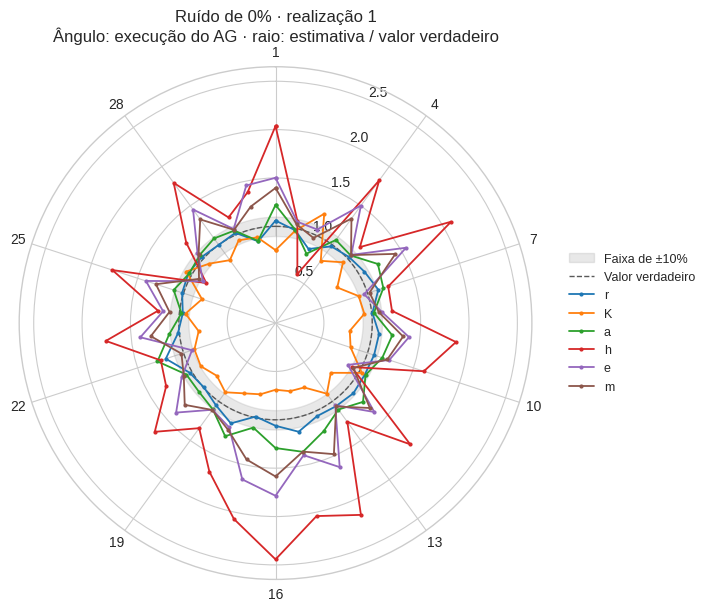

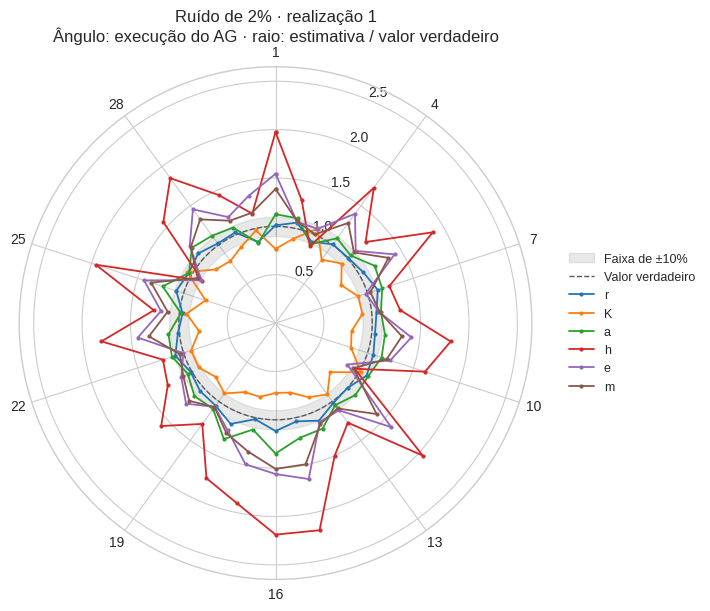

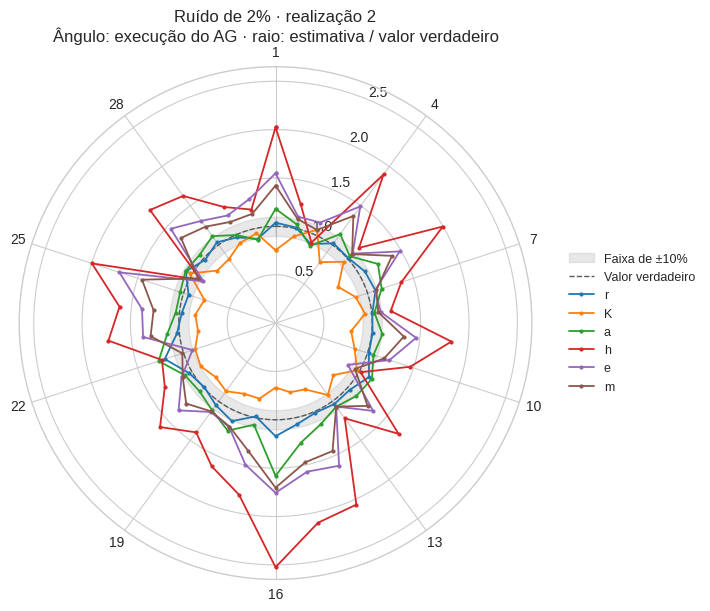

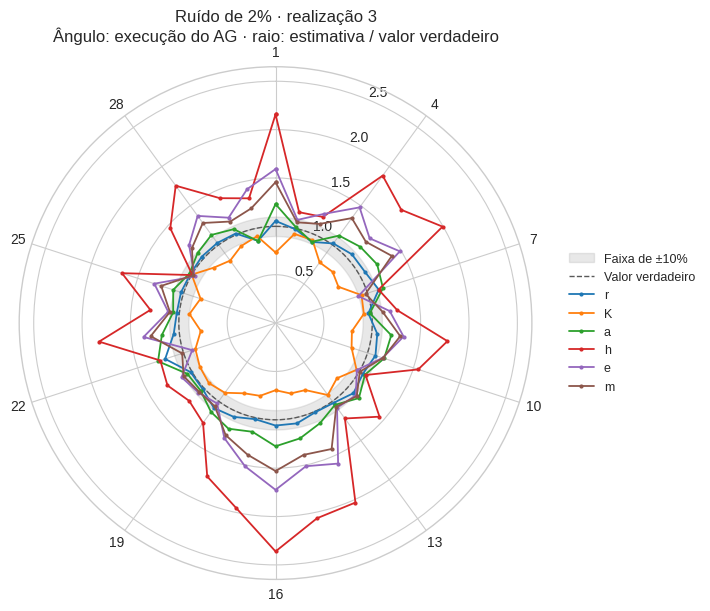

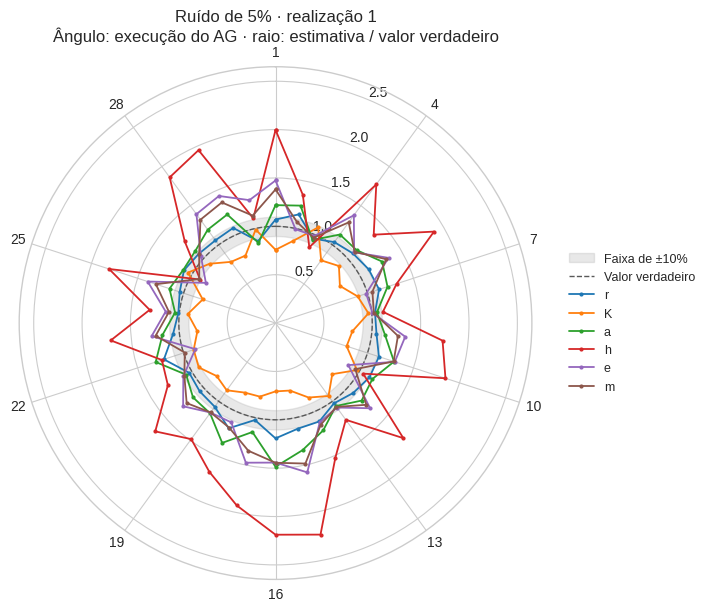

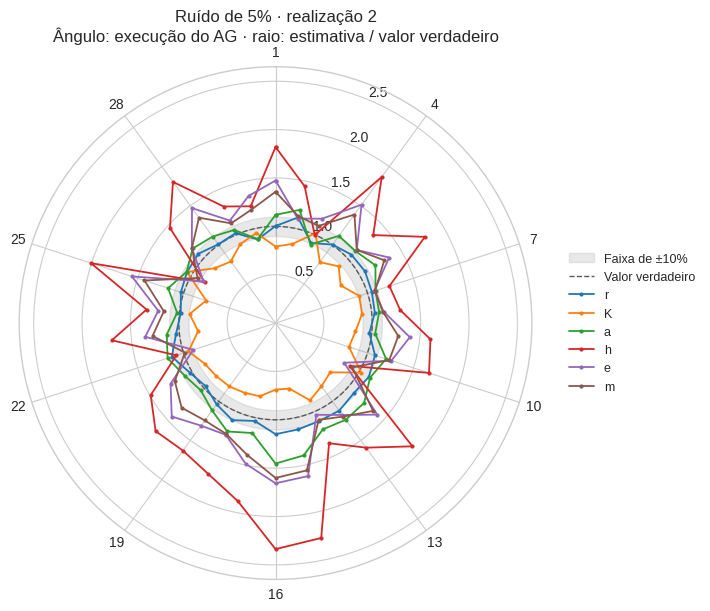

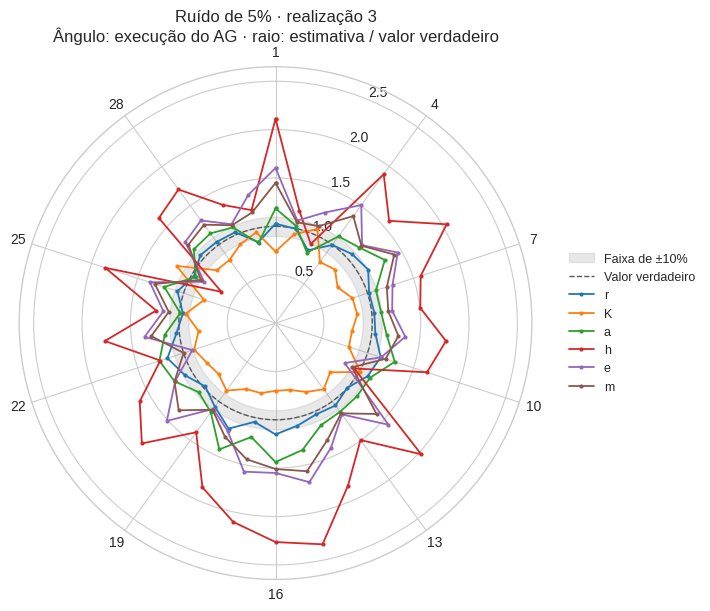

In [29]:
# Cada raio corresponde a uma execução do AG, na ordem registrada.
razoes = tabela_execucoes[NOMES_PARAMETROS].div(theta_true, axis="columns")
tolerancia = CONFIG_PROTOCOLO["tolerancia_sucesso"]
limite_radial = 1.05 * max(razoes.to_numpy().max(), 1 + tolerancia)
volta = np.linspace(0, 2 * np.pi, 361)

for (ruido, realizacao), grupo in tabela_execucoes.groupby(["ruido", "realizacao"]):
    grupo = grupo.sort_values("execucao")
    estimativas = razoes.loc[grupo.index]
    angulos = np.linspace(0, 2 * np.pi, len(grupo), endpoint=False)
    angulos_fechados = np.r_[angulos, 2 * np.pi]

    fig, ax = plt.subplots(figsize=(7, 6), subplot_kw={"projection": "polar"},
                           layout="constrained")
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.fill_between(volta, 1 - tolerancia, 1 + tolerancia, color="0.6",
                    alpha=0.22, label=f"Faixa de ±{tolerancia:.0%}")
    ax.plot(volta, np.ones_like(volta), "--", color="0.35", lw=1,
            label="Valor verdadeiro")

    for nome in NOMES_PARAMETROS:
        valores = estimativas[nome].to_numpy()
        ax.plot(angulos_fechados, np.r_[valores, valores[0]], marker=".",
                markersize=4, lw=1.3, label=nome)

    passo_rotulos = max(1, len(grupo) // 8)
    ax.set_xticks(angulos[::passo_rotulos], grupo["execucao"].iloc[::passo_rotulos])
    ax.set_ylim(0, limite_radial)
    ax.set_title(f"Ruído de {ruido:.0%} · realização {realizacao + 1}\n"
                 "Ângulo: execução do AG · raio: estimativa / valor verdadeiro",
                 pad=18)
    ax.legend(loc="center left", bbox_to_anchor=(1.05, 0.5), fontsize=9)
    plt.show()


### Contribuição dos parâmetros para o erro de ajuste

Os valores SHAP decompõem a diferença entre o objetivo de cada estimativa e o objetivo médio de oito vetores de referência amostrados por hipercubo latino em uma faixa de ±10% dos parâmetros verdadeiros, respeitando os limites de busca. O cálculo é exato para essa referência empírica: avalia os 64 subconjuntos de parâmetros, combinando cada subconjunto com os vetores de referência. As barras mostram a contribuição absoluta média nas execuções de cada cenário. As contribuições com sinal estão em `tabela_shap`. O ranking depende da referência e mede a contribuição para o erro de ajuste. A análise reavalia a EDO e pode demorar alguns minutos.

In [30]:
from shap_objetivo import calcular_shap

# A mesma referência empírica é usada em todos os cenários.
amostrador_shap = qmc.LatinHypercube(d=len(NOMES_PARAMETROS), seed=2026)
raio_referencia_shap = 0.10 * np.abs(theta_true)
limites_inferiores_shap = np.maximum(LIMITES_INFERIORES, theta_true - raio_referencia_shap)
limites_superiores_shap = np.minimum(LIMITES_SUPERIORES, theta_true + raio_referencia_shap)
referencia_shap = qmc.scale(amostrador_shap.random(n=8),
                            limites_inferiores_shap, limites_superiores_shap)

def analisar_shap_cenario(item):
    (ruido, realizacao), grupo = item
    observacoes = resultados_ag[grupo.index[0]]["observacoes"]
    objetivo_cenario = criar_objetivo(observacoes)

    def objetivo(parametros):
        erro = objetivo_cenario(parametros)
        if erro == PENALIDADE:
            raise ValueError(
                f"Simulação inválida em ruído={ruido:.0%}, realização={realizacao + 1}."
            )
        return erro

    estimativas = grupo[NOMES_PARAMETROS].to_numpy()
    base, valores, erros = calcular_shap(objetivo, estimativas, referencia_shap)
    np.testing.assert_allclose(erros, grupo["objetivo"], rtol=1e-9, atol=1e-12)
    return ruido, realizacao, grupo, base, valores

grupos_shap = tabela_execucoes.groupby(["ruido", "realizacao"])
resultados_shap = [analisar_shap_cenario(item) for item in grupos_shap]


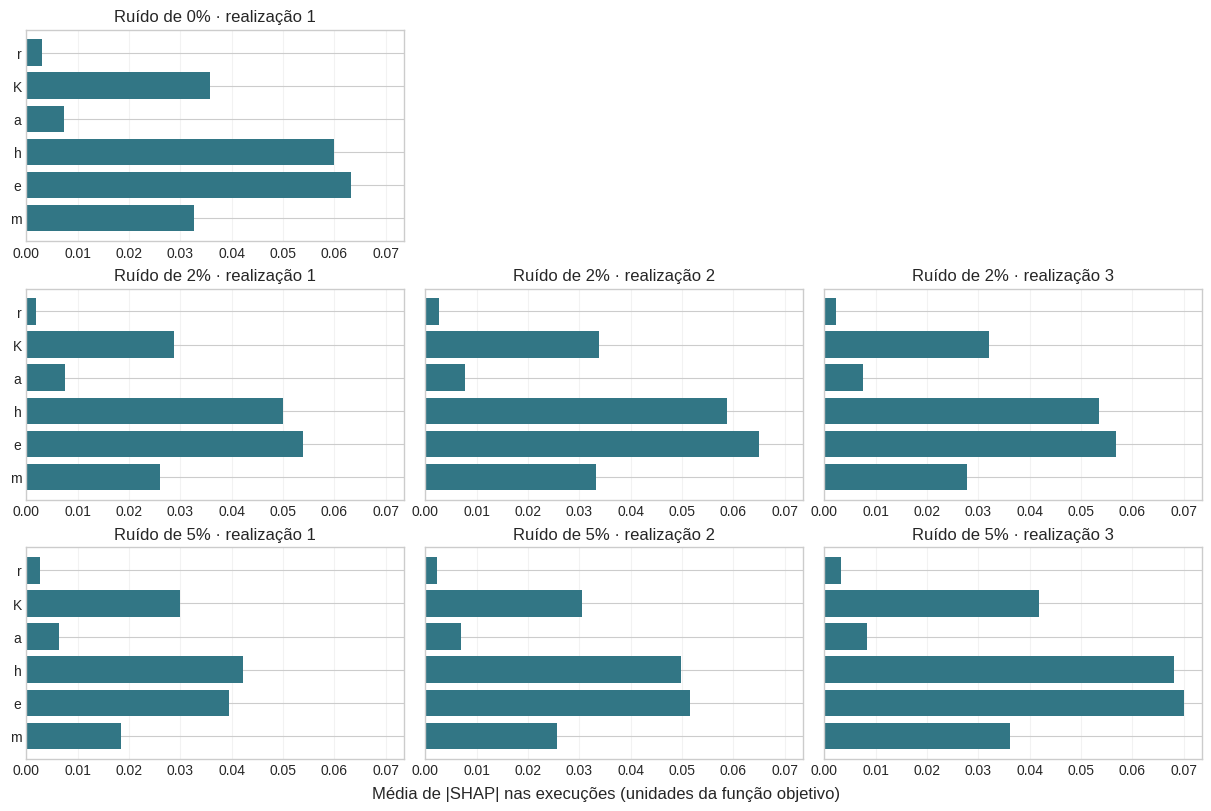

In [31]:
linhas_shap = []
for ruido, realizacao, grupo, base, valores in resultados_shap:
    linhas_shap.append(
        grupo[["ruido", "realizacao", "execucao", "objetivo"]].assign(
            objetivo_referencia=base,
            **dict(zip(NOMES_PARAMETROS, valores.T)),
        )
    )
tabela_shap = pd.concat(linhas_shap, ignore_index=True)

fig, eixos = plt.subplots(3, 3, figsize=(12, 8), sharex=True, sharey=True,
                          layout="constrained")
for ax in eixos.flat:
    ax.set_visible(False)

for ruido, realizacao, _, _, valores in resultados_shap:
    linha = sorted(tabela_shap["ruido"].unique()).index(ruido)
    ax = eixos[linha, realizacao]
    ax.set_visible(True)
    ax.barh(NOMES_PARAMETROS, np.abs(valores).mean(axis=0), color="#327685")
    ax.set_title(f"Ruído de {ruido:.0%} · realização {realizacao + 1}")
    ax.tick_params(axis="x", labelbottom=True)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.25)

eixos[0, 0].invert_yaxis()
fig.supxlabel("Média de |SHAP| nas execuções (unidades da função objetivo)")
plt.show()


## 7. Resumo

Os indicadores abaixo separam explicitamente o ajuste aos dados observados da capacidade de recuperar os parametros usados para gerar os dados.

In [32]:
melhor_linha = tabela_execucoes.loc[indice_melhor]
print(f"Melhor execucao: {int(melhor_linha['execucao'])} (seed={int(melhor_linha['seed'])})")
print(f"Melhor objetivo: {melhor_linha['objetivo']:.6g}")
print(f"Objetivo medio +/- DP: {tabela_objetivo.loc[0, 'media']:.6g} +/- {tabela_objetivo.loc[0, 'desvio_padrao']:.6g}")
print(f"Tempo medio +/- DP: {tabela_tempo.loc[0, 'tempo_medio_segundos']:.3f} +/- {tabela_tempo.loc[0, 'tempo_dp_segundos']:.3f} s")
print(f"Avaliacoes medias: {tabela_cenario['avaliacoes'].mean():.1f}")
display(tabela_parametros)

# Para uma validacao curta, sem alterar a configuracao principal, execute manualmente:
# resultados_teste = executar_experimento(CONFIG_TESTE_RAPIDO, CONFIG_PROTOCOLO_RAPIDO)
print(f"Taxa de sucesso no cenario: {tabela_cenario['sucesso'].mean():.1%}")


Melhor execucao: 2 (seed=3101)
Melhor objetivo: 1.8689e-05
Objetivo medio +/- DP: 0.000452757 +/- 0.000380117
Tempo medio +/- DP: 158.953 +/- 15.333 s
Avaliacoes medias: 14042.1


,verdadeiro,estimativa_media,desvio_padrao,erro_absoluto,erro_relativo
r,1.00,1.03387,0.07200,0.03387,0.03387
K,100.00,86.26027,11.78055,13.73973,0.13740
a,0.05,0.05555,0.00625,0.00555,0.11097
h,0.20,0.30612,0.08971,0.10612,0.53059
e,0.50,0.62990,0.12426,0.12990,0.25980
m,0.50,0.60045,0.08877,0.10045,0.20090


Taxa de sucesso no cenario: 3.3%
